In [21]:
#Imports 
import os
import sys
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F

from PIL import Image

from datasets import load_dataset

from transformers import (
    Sam2Model,
    Sam2Processor,
)

from torchvision import transforms

from tqdm.auto import tqdm

In [22]:

#Paths registry 
PROJECT_ROOT = Path("/home/zahranadeem/thesis")

MODEL_NAME = "facebook/sam2.1-hiera-tiny"

###############################################

AGRICLIP_ROOT = (
    PROJECT_ROOT
    / "agriclip_sam2"
    / "AgriCLIP"
)

ALIGNMENT_DIR = (
    AGRICLIP_ROOT
    / "AgriCLIP_alignment"
)

ALIGNER_PATH = (
    PROJECT_ROOT
    / "vegann_aligner.pth"
)

SAM2_CHECKPOINT = (
    PROJECT_ROOT
    / "sam2_vegann_checkpoints"
    / "best_sam2_vegann_mask_decoder.pt"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "results"
    / "agriclip_attention_guided_sam2"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print("Project:", PROJECT_ROOT)
print("AgriCLIP:", AGRICLIP_ROOT)
print("Aligner:", ALIGNER_PATH)
print("SAM2:", SAM2_CHECKPOINT)


Project: /home/zahranadeem/thesis
AgriCLIP: /home/zahranadeem/thesis/agriclip_sam2/AgriCLIP
Aligner: /home/zahranadeem/thesis/vegann_aligner.pth
SAM2: /home/zahranadeem/thesis/sam2_vegann_checkpoints/best_sam2_vegann_mask_decoder.pt


In [23]:
#Checking the device 
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print(device)

cuda


In [24]:
#Loading VegAnn and split 
vegann = load_dataset(
    "simonMadec/VegAnn"
)

split = vegann["train"].train_test_split(
    test_size=0.20,
    seed=42
)

train_hf = split["train"]
val_hf = split["test"]

print(len(train_hf))
print(len(val_hf))

3020
755


In [25]:
#Detecting image and mask coloums 
columns = vegann["train"].column_names

IMAGE_KEY = next(
    x
    for x in columns
    if x in ["image", "images", "rgb"]
)

MASK_KEY = next(
    x
    for x in columns
    if x in [
        "mask",
        "masks",
        "label",
        "labels",
        "segmentation_mask",
    ]
)

print(IMAGE_KEY)
print(MASK_KEY)

image
mask


In [26]:
#Image helper
def get_image(index, split=val_hf):

    sample = split[index]

    image = sample[IMAGE_KEY]

    if not isinstance(image, Image.Image):
        image = Image.fromarray(np.array(image))

    return image.convert("RGB")


def get_mask(index, split=val_hf):

    sample = split[index]

    mask = np.array(sample[MASK_KEY])

    mask = (mask > 0).astype(np.uint8)

    return mask

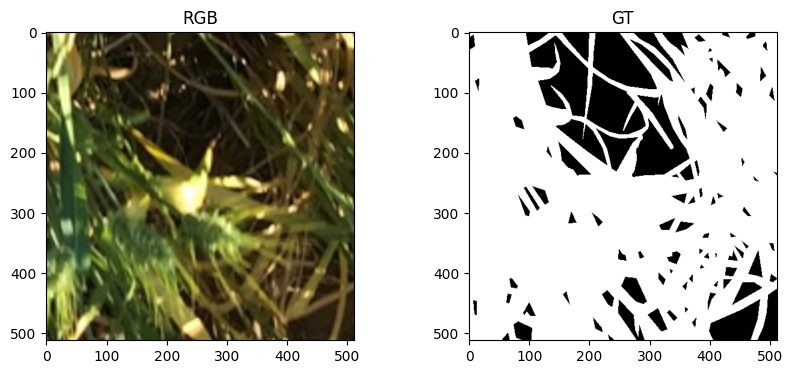

In [27]:
#Visualize image and mask 
image = get_image(0)
mask = get_mask(0)

plt.figure(figsize=(10,4))

plt.subplot(121)
plt.imshow(image)
plt.title("RGB")

plt.subplot(122)
plt.imshow(mask,cmap="gray")
plt.title("GT")

plt.show()

In [28]:
#Transform the image 
IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406,
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225,
]

dino_transform = transforms.Compose([

    transforms.Resize(
        (224,224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD,
    ),
])

In [29]:
#Load DINO 
dino_model = torch.hub.load(
    "facebookresearch/dino:main",
    "dino_resnet50",
    pretrained=True,
)

dino_model.eval()
dino_model.to(device)

for parameter in dino_model.parameters():
    parameter.requires_grad = False

print("DINO loaded.")

Using cache found in /home/zahranadeem/.cache/torch/hub/facebookresearch_dino_main


DINO loaded.


In [30]:
import os

print(os.path.exists("/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment/TextToConcept.py"))

True


In [31]:
import sys

ALIGNMENT_DIR = "/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment"

if ALIGNMENT_DIR not in sys.path:
    sys.path.append(ALIGNMENT_DIR)

from TextToConcept import TextToConcept
from LinearAligner import LinearAligner

print("Imported successfully")

ModuleNotFoundError: No module named 'clip'

In [ ]:
text_to_concept = TextToConcept(
    dino_model,
    "dino_resnet50",
)

text_to_concept.load_linear_aligner(
    str(ALIGNER_PATH)
)

aligner = text_to_concept.linear_aligner

print("VegAnn aligner loaded.")
print("W shape:", tuple(aligner.W.shape))
print("b shape:", tuple(aligner.b.shape))

VegAnn aligner loaded.
W shape: (512, 2048)
b shape: (512,)


In [ ]:
#Register a hook on Dino layer4
captured_feature_map = None


def capture_layer4_output(module, inputs, output):
    global captured_feature_map
    captured_feature_map = output.detach()


hook_handle = dino_model.layer4.register_forward_hook(
    capture_layer4_output
)

print("DINO layer4 hook registered.")

DINO layer4 hook registered.


In [ ]:
#Extract spatial DINO descriptors automatically wheter 7x7 or other
@torch.no_grad()
def extract_dino_patch_features(pil_image):
    
    

    global captured_feature_map

    captured_feature_map = None

    image_tensor = dino_transform(
        pil_image
    ).unsqueeze(0).to(device)

    _ = dino_model(image_tensor)

    if captured_feature_map is None:
        raise RuntimeError(
            "The layer4 hook did not capture a feature map."
        )

    if captured_feature_map.ndim != 4:
        raise RuntimeError(
            "Expected feature map shape (B, C, H, W), "
            f"but received {captured_feature_map.shape}."
        )

    _, channels, grid_h, grid_w = captured_feature_map.shape

    patch_features = (
        captured_feature_map[0]
        .permute(1, 2, 0)
        .reshape(grid_h * grid_w, channels)
        .contiguous()
    )

    return patch_features, grid_h, grid_w

In [ ]:
#Extract patches 
sample_index = 0

image = get_image(
    sample_index,
    split=val_hf,
)

gt_mask = get_mask(
    sample_index,
    split=val_hf,
)

patch_features, grid_h, grid_w = extract_dino_patch_features(
    image
)

print("Image size:", image.size)
print("Feature grid:", grid_h, "x", grid_w)
print("Patch features:", patch_features.shape)

Image size: (512, 512)
Feature grid: 7 x 7
Patch features: torch.Size([49, 2048])


In [ ]:
print(
    "DINO feature dim:",
    patch_features.shape
)

print(
    "Aligner input:",
    aligner.W.shape
)

DINO feature dim: torch.Size([49, 2048])
Aligner input: torch.Size([512, 2048])


In [ ]:
#Project patches using VegAnn aligner 
#Better to project first and then normalize in a shared concept space
@torch.no_grad()
def align_patch_features(patch_features):
    patch_features = patch_features.float().to(device)

    aligned_features = aligner.get_aligned_representation(
        patch_features
    )

    aligned_features = F.normalize(
        aligned_features,
        dim=1,
    )

    return aligned_features


aligned_patch_features = align_patch_features(
    patch_features
)

print("Aligned patch features:", aligned_patch_features.shape)

Aligned patch features: torch.Size([49, 512])


In [ ]:
#Define prompts 
VEGETATION_PROMPTS = [
    "A crop field populated by healthy plants, captured from a nadir view using a handheld camera.",
    "An agricultural scene showing healthy crops growing in the field, captured from a nadir view using a handheld camera.",
    "A field image containing healthy crop vegetation, captured from a nadir view using a handheld camera.",
    "An aerial agricultural image of dense green crop plants, captured from a nadir view using a handheld camera.",
    "Healthy crop canopy covering the field, captured from a nadir view using a handheld camera.",
    "Agricultural vegetation viewed from above, captured from a nadir view using a handheld camera.",
]

for prompt in VEGETATION_PROMPTS:
    print("+", prompt)

+ A crop field populated by healthy plants, captured from a nadir view using a handheld camera.
+ An agricultural scene showing healthy crops growing in the field, captured from a nadir view using a handheld camera.
+ A field image containing healthy crop vegetation, captured from a nadir view using a handheld camera.
+ An aerial agricultural image of dense green crop plants, captured from a nadir view using a handheld camera.
+ Healthy crop canopy covering the field, captured from a nadir view using a handheld camera.
+ Agricultural vegetation viewed from above, captured from a nadir view using a handheld camera.


In [ ]:
#Encode and average vegetation prompts 
@torch.no_grad()
def encode_prompt_set(prompts):
    embeddings = []

    for prompt in prompts:
        embedding = text_to_concept.encode_text(
            [[prompt]]
        )

        if isinstance(embedding, np.ndarray):
            embedding = torch.from_numpy(embedding)

        if not torch.is_tensor(embedding):
            raise TypeError(
                "encode_text returned an unsupported type: "
                f"{type(embedding)}"
            )

        embedding = (
            embedding
            .detach()
            .float()
            .to(device)
            .reshape(-1)
        )

        embeddings.append(embedding)

    embeddings = torch.stack(
        embeddings,
        dim=0,
    )

    embeddings = F.normalize(
        embeddings,
        dim=1,
    )

    mean_embedding = embeddings.mean(
        dim=0,
    )

    mean_embedding = F.normalize(
        mean_embedding,
        dim=0,
    )

    return embeddings, mean_embedding


vegetation_text_embeddings, vegetation_embedding = encode_prompt_set(
    VEGETATION_PROMPTS
)

print(
    "Individual text embeddings:",
    vegetation_text_embeddings.shape,
)

print(
    "Mean vegetation embedding:",
    vegetation_embedding.shape,
)

Individual text embeddings: torch.Size([6, 512])
Mean vegetation embedding: torch.Size([512])


In [ ]:
import os

ALIGNMENT_DIR = "/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment"

print(os.listdir(ALIGNMENT_DIR))

['util.py', 'LinearAligner.py', 'AgriClip_zeroshot.py', 'train_linear_aligner.py', 'my_utils.py', 'TextToConcept.py', 'AgriClip_zeroshot.ipynb', '__pycache__']


In [ ]:
import sys
from pathlib import Path

ALIGNMENT_DIR = Path(
    "/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment"
)

if str(ALIGNMENT_DIR) not in sys.path:
    sys.path.insert(0, str(ALIGNMENT_DIR))

print(sys.path[0])

/usr/lib/python310.zip


In [ ]:
from TextToConcept import TextToConcept
from LinearAligner import LinearAligner

print("Imported successfully")

Imported successfully


In [ ]:
print(type(text_to_concept))
print(text_to_concept.__dict__.keys())

<class 'TextToConcept.TextToConcept'>
dict_keys(['model', 'model_name', 'device', 'clip_model', 'saved_dsets', 'linear_aligner'])


In [ ]:
print(hasattr(text_to_concept, "tokenizer"))
print(hasattr(text_to_concept, "model"))

if hasattr(text_to_concept, "tokenizer"):
    print(type(text_to_concept.tokenizer))

if hasattr(text_to_concept, "model"):
    print(type(text_to_concept.model))

False
True
<class 'torchvision.models.resnet.ResNet'>


In [ ]:
print("patch_features:", "patch_features" in globals())
print("aligner:", "aligner" in globals())
print("embedding:", "embedding" in globals())
print("patch_scores:", "patch_scores" in globals())

patch_features: True
aligner: True
embedding: False
patch_scores: True


In [ ]:
# Compute AgriCLIP patch-text similarity scores

with torch.no_grad():

    patch_scores = (
        aligned_patch_features 
        @ vegetation_embedding
    )

print("Patch scores shape:", patch_scores.shape)
print("Min:", patch_scores.min().item())
print("Max:", patch_scores.max().item())

Patch scores shape: torch.Size([49])
Min: 0.3816167712211609
Max: 0.8209817409515381


In [ ]:
TOP_K = 8

scores = patch_scores.cpu().numpy()

sorted_indices = np.argsort(scores)[::-1]

topk_indices = sorted_indices[:TOP_K]

print("Top-K patch indices:")
print(topk_indices)

print("Scores:")
print(scores[topk_indices])

Top-K patch indices:
[19 10  8 26  9 15 22 11]
Scores:
[0.82098174 0.81782067 0.8113041  0.8109801  0.7962588  0.790547
 0.78683347 0.77645105]


In [ ]:
PATCH_ROWS = 7
PATCH_COLS = 7

H, W = image.size[1], image.size[0]

patch_h = H / PATCH_ROWS
patch_w = W / PATCH_COLS

boxes = []

for idx in topk_indices:

    r = idx // PATCH_COLS
    c = idx % PATCH_COLS

    x1 = int(c * patch_w)
    y1 = int(r * patch_h)

    x2 = int((c + 1) * patch_w)
    y2 = int((r + 1) * patch_h)

    boxes.append([x1, y1, x2, y2])

boxes = np.array(boxes)

print(boxes)

[[365 146 438 219]
 [219  73 292 146]
 [ 73  73 146 146]
 [365 219 438 292]
 [146  73 219 146]
 [ 73 146 146 219]
 [ 73 219 146 292]
 [292  73 365 146]]


In [ ]:
xmin = boxes[:,0].min()
ymin = boxes[:,1].min()

xmax = boxes[:,2].max()
ymax = boxes[:,3].max()

merged_box = np.array(
    [
        xmin,
        ymin,
        xmax,
        ymax
    ],
    dtype=np.int32
)

print(merged_box)

NameError: name 'boxes' is not defined

In [ ]:
margin = 25

xmin = max(0, xmin - margin)
ymin = max(0, ymin - margin)

xmax = min(W-1, xmax + margin)
ymax = min(H-1, ymax + margin)

merged_box = np.array(
    [
        xmin,
        ymin,
        xmax,
        ymax
    ]
)

print(merged_box)

[ 48  48 463 317]


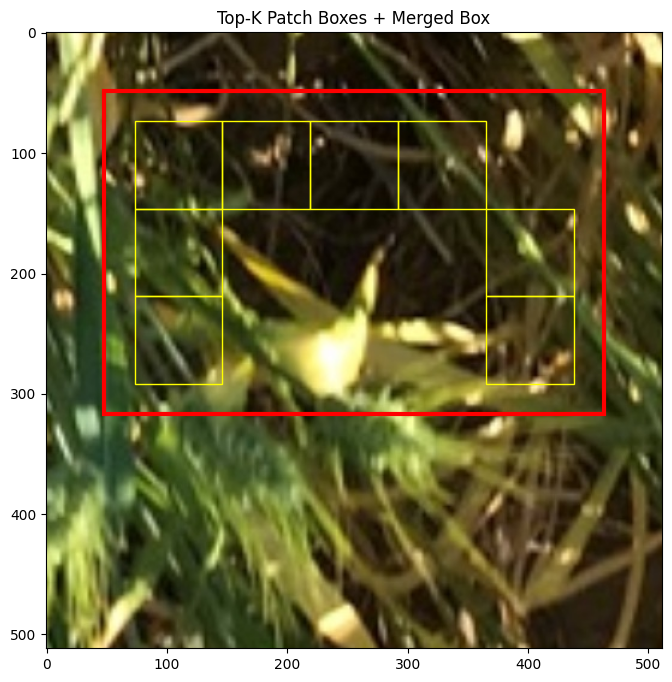

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(8,8))

ax.imshow(image)

rect = patches.Rectangle(

    (merged_box[0], merged_box[1]),

    merged_box[2]-merged_box[0],

    merged_box[3]-merged_box[1],

    linewidth=3,

    edgecolor="red",

    facecolor="none",

)

ax.add_patch(rect)

for b in boxes:

    rect = patches.Rectangle(

        (b[0], b[1]),

        b[2]-b[0],

        b[3]-b[1],

        linewidth=1,

        edgecolor="yellow",

        facecolor="none",

    )

    ax.add_patch(rect)

plt.title("Top-K Patch Boxes + Merged Box")

plt.show()

In [ ]:
print("Merged Box:", merged_box)

print("Image size:", image.size)

print("GT foreground:", gt_mask.sum())

Merged Box: [ 48  48 463 317]
Image size: (512, 512)
GT foreground: 208628


In [ ]:
#Load fine tuned SAM2 model 
sam2_processor = Sam2Processor.from_pretrained(
    MODEL_NAME
)

sam2_model = Sam2Model.from_pretrained(
    MODEL_NAME
)

sam2_checkpoint = torch.load(
    SAM2_CHECKPOINT,
    map_location="cpu",
)

print("SAM2 checkpoint type:", type(sam2_checkpoint))

if (
    isinstance(sam2_checkpoint, dict)
    and "mask_decoder_state_dict" in sam2_checkpoint
):
    mask_decoder_state_dict = sam2_checkpoint[
        "mask_decoder_state_dict"
    ]
elif isinstance(sam2_checkpoint, dict):
    # Supports a checkpoint that directly contains decoder weights.
    mask_decoder_state_dict = sam2_checkpoint
else:
    raise TypeError(
        "Unsupported SAM2 checkpoint structure."
    )

load_result = sam2_model.mask_decoder.load_state_dict(
    mask_decoder_state_dict,
    strict=True,
)

sam2_model = sam2_model.to(device)
sam2_model.eval()

print("Fine-tuned SAM2 mask decoder loaded.")
print(load_result)

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

SAM2 checkpoint type: <class 'dict'>
Fine-tuned SAM2 mask decoder loaded.
<All keys matched successfully>


In [ ]:
#Basic Model paramter count 
def count_parameters(model):
    total = sum(
        p.numel()
        for p in model.parameters()
    )

    trainable = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    return total, trainable


sam2_total_params, sam2_trainable_params = count_parameters(
    sam2_model
)

dino_total_params, dino_trainable_params = count_parameters(
    dino_model
)


print("DINO")
print(
    f"Total parameters: "
    f"{dino_total_params / 1e6:.2f} M"
)

print(
    f"Trainable parameters: "
    f"{dino_trainable_params / 1e6:.2f} M"
)


print("\nSAM2")
print(
    f"Total parameters: "
    f"{sam2_total_params / 1e6:.2f} M"
)

print(
    f"Trainable parameters: "
    f"{sam2_trainable_params / 1e6:.2f} M"
)

DINO
Total parameters: 23.51 M
Trainable parameters: 0.00 M

SAM2
Total parameters: 31.44 M
Trainable parameters: 31.44 M


In [ ]:
#GPU memory utility 
def get_gpu_memory():

    if not torch.cuda.is_available():
        return None

    allocated = (
        torch.cuda.memory_allocated(device)
        / (1024 ** 3)
    )

    reserved = (
        torch.cuda.memory_reserved(device)
        / (1024 ** 3)
    )

    peak = (
        torch.cuda.max_memory_allocated(device)
        / (1024 ** 3)
    )

    return {
        "allocated_gb": allocated,
        "reserved_gb": reserved,
        "peak_gb": peak,
    }

In [ ]:
#Reser GPU memory statistics 
if torch.cuda.is_available():

    torch.cuda.empty_cache()

    torch.cuda.reset_peak_memory_stats(
        device
    )

print("GPU memory statistics reset.")

GPU memory statistics reset.


In [ ]:
#SSAM2 inference time 
import time

sample_index = 0

sample_image = get_image(
    sample_index,
    split=val_hf
)

sample_gt = get_mask(
    sample_index,
    split=val_hf
)

# Use the AgriCLIP-generated box
sample_box = merged_box

NameError: name 'merged_box' is not defined

In [ ]:
if torch.cuda.is_available():

    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats(device)

    torch.cuda.synchronize()


start_time = time.perf_counter()


sample_pred, sample_confidence = sam2_predict_box(
    sample_image,
    sample_box
)


if torch.cuda.is_available():
    torch.cuda.synchronize()


end_time = time.perf_counter()


inference_time = end_time - start_time


memory = get_gpu_memory()


print(
    f"SAM2 inference time: "
    f"{inference_time * 1000:.2f} ms"
)

if memory is not None:

    print(
        f"Peak GPU memory: "
        f"{memory['peak_gb']:.3f} GB"
    )

NameError: name 'sam2_predict_box' is not defined

In [ ]:
#Measure repeated inference 
import time

NUM_TIMING_IMAGES = min(
    50,
    len(val_hf)
)

timing_times = []

if torch.cuda.is_available():

    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats(device)


for idx in tqdm(
    range(NUM_TIMING_IMAGES),
    desc="Timing SAM2"
):

    image = get_image(
        idx,
        split=val_hf
    )

    # For timing, use your AgriCLIP box
    # If merged_box is generated per image in your
    # full pipeline, use that image's box here.

    gt_mask = get_mask(
        idx,
        split=val_hf
    )

    # Example: generate the box here
    patch_features, grid_h, grid_w = (
        extract_dino_patch_features(image)
    )

    aligned_patch_features = (
        align_patch_features(
            patch_features
        )
    )

    patch_scores = torch.matmul(
        aligned_patch_features,
        vegetation_embedding
    )

    scores = (
        patch_scores
        .detach()
        .cpu()
        .numpy()
    )

    topk_indices = np.argsort(
        scores
    )[::-1][:TOP_K]

    # Create patch boxes
    H, W = image.size[1], image.size[0]

    patch_h = H / grid_h
    patch_w = W / grid_w

    boxes = []

    for patch_idx in topk_indices:

        r = patch_idx // grid_w
        c = patch_idx % grid_w

        x1 = int(c * patch_w)
        y1 = int(r * patch_h)

        x2 = int((c + 1) * patch_w)
        y2 = int((r + 1) * patch_h)

        boxes.append(
            [x1, y1, x2, y2]
        )

    boxes = np.array(boxes)

    xmin = boxes[:, 0].min()
    ymin = boxes[:, 1].min()
    xmax = boxes[:, 2].max()
    ymax = boxes[:, 3].max()

    margin = 25

    xmin = max(
        0,
        xmin - margin
    )

    ymin = max(
        0,
        ymin - margin
    )

    xmax = min(
        W - 1,
        xmax + margin
    )

    ymax = min(
        H - 1,
        ymax + margin
    )

    agriclip_box = np.array(
        [
            xmin,
            ymin,
            xmax,
            ymax
        ],
        dtype=np.int32
    )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start = time.perf_counter()

    _ = sam2_predict_box(
        image,
        agriclip_box
    )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    end = time.perf_counter()

    timing_times.append(
        end - start
    )


mean_time = np.mean(timing_times)
std_time = np.std(timing_times)

print(
    f"Mean SAM2 inference time: "
    f"{mean_time * 1000:.2f} ms"
)

print(
    f"Std: "
    f"{std_time * 1000:.2f} ms"
)

print(
    f"FPS: "
    f"{1 / mean_time:.2f}"
)

memory = get_gpu_memory()

if memory is not None:

    print(
        f"Peak GPU memory: "
        f"{memory['peak_gb']:.3f} GB"
    )

In [ ]:
#GT box 
"""ys, xs = np.where(gt_mask > 0)

gt_box = np.array([
    xs.min(),
    ys.min(),
    xs.max(),
    ys.max()
], dtype=np.int32)

print(gt_box)"""

'ys, xs = np.where(gt_mask > 0)\n\ngt_box = np.array([\n    xs.min(),\n    ys.min(),\n    xs.max(),\n    ys.max()\n], dtype=np.int32)\n\nprint(gt_box)'

In [ ]:
checkpoint = torch.load(
    SAM2_CHECKPOINT,
    map_location=device
)

print(checkpoint.keys())

dict_keys(['epoch', 'model_name', 'mask_decoder_state_dict', 'optimizer_state_dict', 'best_mean_iou', 'history'])


In [ ]:
sam2_inputs = sam2_processor(

    images=image,

    input_boxes=[[merged_box]],
    #input_boxes = [[gt_box]],

    return_tensors="pt",

)

sam2_inputs = {

    k: v.to(device)

    if torch.is_tensor(v)

    else v

    for k, v in sam2_inputs.items()

}

with torch.no_grad():

    sam2_outputs = sam2_model(
        **sam2_inputs
    )

print(sam2_outputs.pred_masks.shape)
print(sam2_outputs.iou_scores.shape)

torch.Size([1, 1, 3, 256, 256])
torch.Size([1, 1, 3])


In [ ]:
print(sam2_inputs.keys())

dict_keys(['pixel_values', 'original_sizes', 'input_boxes'])


In [ ]:
# Pick best candidate

best_index = sam2_outputs.iou_scores[0,0].argmax()

print("Best candidate:", best_index.item())

# Raw logits

best_logits = sam2_outputs.pred_masks[
    0,
    0,
    best_index
]

print(best_logits.shape)

# Convert to probability

best_mask_probability = torch.sigmoid(best_logits)

# Resize to original image size

best_mask_probability = torch.nn.functional.interpolate(

    best_mask_probability.unsqueeze(0).unsqueeze(0),

    size=gt_mask.shape,

    mode="bilinear",

    align_corners=False,

).squeeze()

best_mask = (

    best_mask_probability > 0.15

).cpu().numpy().astype(np.uint8)

print(best_mask.shape)

Best candidate: 2
torch.Size([256, 256])
(512, 512)


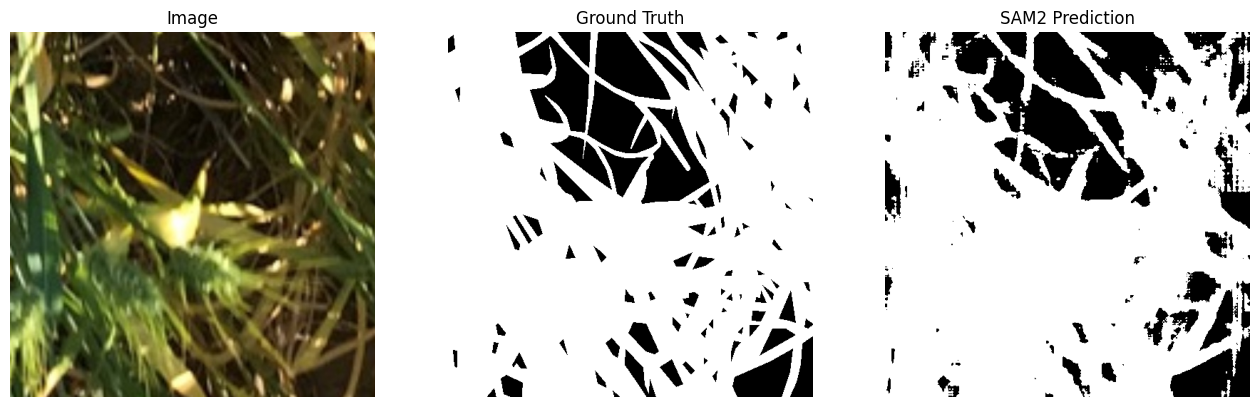

In [ ]:
plt.figure(figsize=(16,5))

plt.subplot(131)
plt.imshow(image)
plt.title("Image")
plt.axis("off")

plt.subplot(132)
plt.imshow(gt_mask,cmap="gray")
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(133)
plt.imshow(best_mask,cmap="gray")
plt.title("SAM2 Prediction")
plt.axis("off")

plt.show()

In [ ]:
#Select and decode the best SAM2 candidate 
best_candidate_index = int(
    sam2_outputs.iou_scores[0, 0]
    .argmax()
    .item()
)

best_mask_logits = sam2_outputs.pred_masks[
    0,
    0,
    best_candidate_index,
]

best_mask_probability = torch.sigmoid(
    best_mask_logits
)

original_height = int(
    sam2_inputs["original_sizes"][0, 0].item()
)
original_width = int(
    sam2_inputs["original_sizes"][0, 1].item()
)

best_mask_probability = F.interpolate(
    best_mask_probability[None, None],
    size=(original_height, original_width),
    mode="bilinear",
    align_corners=False,
)[0, 0]

pred_mask = (
    best_mask_probability >= 0.5
).detach().cpu().numpy().astype(np.uint8)

print("Selected SAM2 candidate:", best_candidate_index)
print(
    "Predicted IoU confidence:",
    float(
        sam2_outputs.iou_scores[
            0,
            0,
            best_candidate_index,
        ].item()
    ),
)
print("Prediction shape:", pred_mask.shape)
print("Foreground pixels:", int(pred_mask.sum()))

Selected SAM2 candidate: 2
Predicted IoU confidence: 0.9179320931434631
Prediction shape: (512, 512)
Foreground pixels: 164145


Min : 2.7390915e-06
Max : 0.9999696
Mean: 0.61813366
Std : 0.39227828


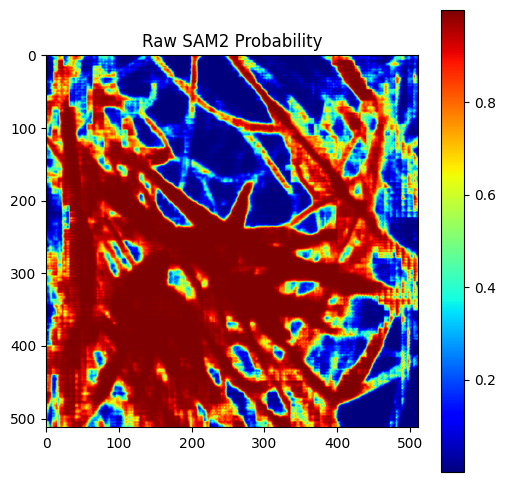

In [ ]:
# Visualize raw SAM2 probability

prob = best_mask_probability.detach().cpu().numpy()

print("Min :", prob.min())
print("Max :", prob.max())
print("Mean:", prob.mean())
print("Std :", prob.std())

plt.figure(figsize=(6,6))
plt.imshow(prob, cmap="jet")
plt.colorbar()
plt.title("Raw SAM2 Probability")
plt.show()

In [ ]:
#Define segmentation metrics 
def compute_binary_metrics(prediction, ground_truth):
    prediction = prediction.astype(bool)
    ground_truth = ground_truth.astype(bool)

    intersection = np.logical_and(
        prediction,
        ground_truth,
    ).sum()

    union = np.logical_or(
        prediction,
        ground_truth,
    ).sum()

    pred_pixels = prediction.sum()
    gt_pixels = ground_truth.sum()

    iou = (
        intersection / union
        if union > 0
        else 1.0
    )

    dice_denominator = pred_pixels + gt_pixels

    dice = (
        2.0 * intersection / dice_denominator
        if dice_denominator > 0
        else 1.0
    )

    precision = (
        intersection / pred_pixels
        if pred_pixels > 0
        else 0.0
    )

    recall = (
        intersection / gt_pixels
        if gt_pixels > 0
        else 0.0
    )

    return {
        "iou": float(iou),
        "dice": float(dice),
        "precision": float(precision),
        "recall": float(recall),
        "intersection": int(intersection),
        "union": int(union),
        "pred_pixels": int(pred_pixels),
        "gt_pixels": int(gt_pixels),
    }


metrics = compute_binary_metrics(
    pred_mask,
    gt_mask,
)

for name, value in metrics.items():
    if isinstance(value, float):
        print(f"{name:>14}: {value:.4f}")
    else:
        print(f"{name:>14}: {value}")

           iou: 0.7545
          dice: 0.8601
     precision: 0.9766
        recall: 0.7684
  intersection: 160306
         union: 212467
   pred_pixels: 164145
     gt_pixels: 208628


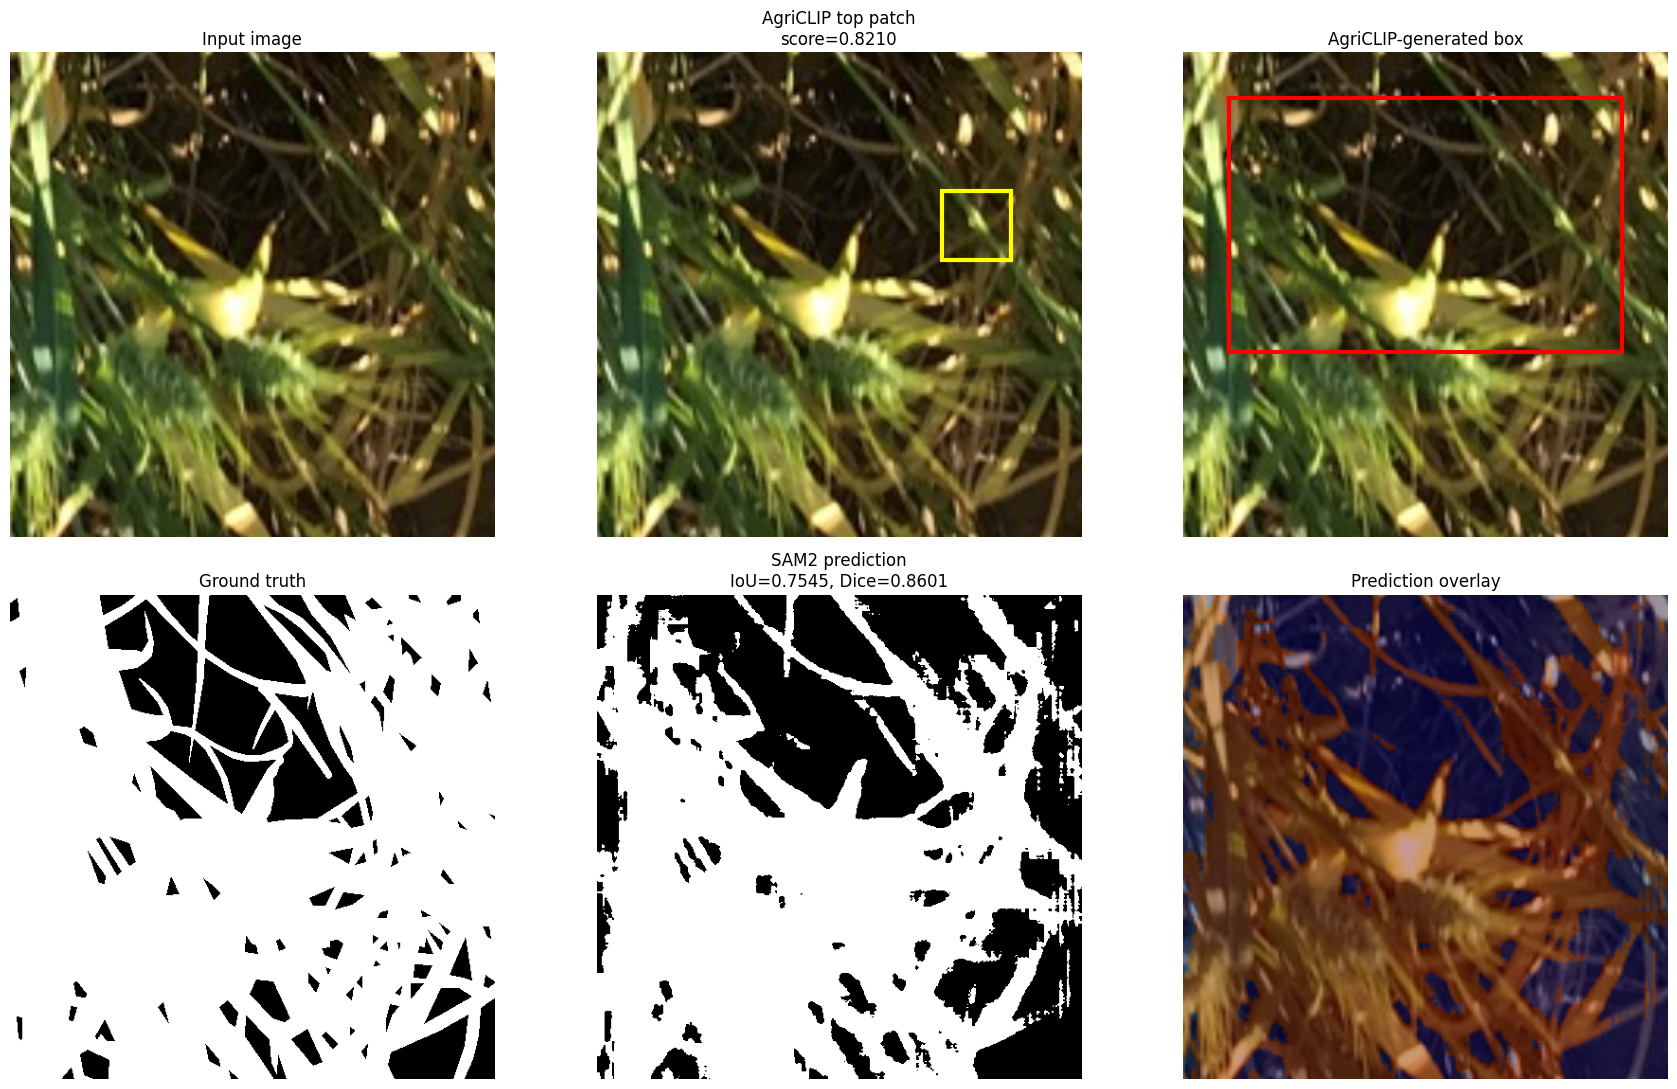

In [ ]:
# Visualize the complete result

fig, ax = plt.subplots(
    2,
    3,
    figsize=(18, 11),
)

# Image
ax[0, 0].imshow(image)
ax[0, 0].set_title("Input image")
ax[0, 0].axis("off")



# Winning patch
best_patch = boxes[0]

ax[0, 1].imshow(image)

ax[0, 1].add_patch(
    plt.Rectangle(
        (best_patch[0], best_patch[1]),
        best_patch[2] - best_patch[0],
        best_patch[3] - best_patch[1],
        fill=False,
        edgecolor="yellow",
        linewidth=3,
    )
)

ax[0, 1].set_title(
    f"AgriCLIP top patch\nscore={scores[topk_indices[0]]:.4f}"
)

ax[0, 1].axis("off")


# Expanded AgriCLIP box
ax[0, 2].imshow(image)

ax[0, 2].add_patch(
    plt.Rectangle(
        (merged_box[0], merged_box[1]),
        merged_box[2] - merged_box[0],
        merged_box[3] - merged_box[1],
        fill=False,
        edgecolor="red",
        linewidth=3,
    )
)

ax[0, 2].set_title(
    "AgriCLIP-generated box"
)

ax[0, 2].axis("off")


# Ground truth
ax[1, 0].imshow(
    gt_mask,
    cmap="gray",
)

ax[1, 0].set_title(
    "Ground truth"
)

ax[1, 0].axis("off")


# Prediction
ax[1, 1].imshow(
    pred_mask,
    cmap="gray",
)

ax[1, 1].set_title(
    f"SAM2 prediction\n"
    f"IoU={metrics['iou']:.4f}, "
    f"Dice={metrics['dice']:.4f}"
)

ax[1, 1].axis("off")


# Overlay
ax[1, 2].imshow(image)

ax[1, 2].imshow(
    pred_mask,
    cmap="jet",
    alpha=0.40,
)

ax[1, 2].set_title(
    "Prediction overlay"
)

ax[1, 2].axis("off")


plt.tight_layout()
plt.show()

In [ ]:
#save the result 
sample_output_dir = (
    OUTPUT_DIR
    / f"sample_{sample_index:04d}"
)

sample_output_dir.mkdir(
    parents=True,
    exist_ok=True,
)

cv2.imwrite(
    str(sample_output_dir / "ground_truth.png"),
    gt_mask.astype(np.uint8) * 255,
)

cv2.imwrite(
    str(sample_output_dir / "prediction.png"),
    pred_mask.astype(np.uint8) * 255,
)

np.save(
    sample_output_dir / "patch_scores.npy",
    patch_scores.detach().cpu().numpy(),
)

np.save(
    sample_output_dir / "agriclip_box.npy",
    merged_box,
)

with open(
    sample_output_dir / "metrics.txt",
    "w",
    encoding="utf-8",
) as file:
    for name, value in metrics.items():
        file.write(f"{name}: {value}\n")

print("Saved result to:")
print(sample_output_dir)

Saved result to:
/home/zahranadeem/thesis/results/agriclip_attention_guided_sam2/sample_0000


In [ ]:
#Validation Output folders 
from pathlib import Path
import pandas as pd
import cv2
import numpy as np
import torch
from tqdm.auto import tqdm


VAL_OUTPUT_DIR = (
    PROJECT_ROOT
    / "results"
    / "agriclip_sam2_validation"
)

VAL_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MASK_DIR = VAL_OUTPUT_DIR / "predictions"
BOX_DIR = VAL_OUTPUT_DIR / "boxes"

MASK_DIR.mkdir(
    exist_ok=True
)

BOX_DIR.mkdir(
    exist_ok=True)


print(VAL_OUTPUT_DIR)

/home/zahranadeem/thesis/results/agriclip_sam2_validation


In [ ]:
#Replaces manual Top K code 
@torch.no_grad()
def generate_agriclip_box(
    image,
    top_k=8
):

    # Extract DINO patches
    patch_features, grid_h, grid_w = extract_dino_patch_features(
        image
    )


    # Align to AgriCLIP space
    aligned_features = align_patch_features(
        patch_features
    )


    # Patch-text similarity
    patch_scores = (
        aligned_features 
        @ vegetation_embedding
    )


    scores = patch_scores.cpu().numpy()


    # Top-K patches
    topk_indices = np.argsort(scores)[::-1][:top_k]


    H, W = image.size[1], image.size[0]


    patch_h = H / grid_h
    patch_w = W / grid_w


    boxes = []


    for idx in topk_indices:

        r = idx // grid_w
        c = idx % grid_w


        x1 = int(c * patch_w)
        y1 = int(r * patch_h)

        x2 = int((c+1) * patch_w)
        y2 = int((r+1) * patch_h)


        boxes.append(
            [
                x1,
                y1,
                x2,
                y2
            ]
        )


    boxes = np.array(boxes)


    # Merge boxes
    xmin = boxes[:,0].min()
    ymin = boxes[:,1].min()

    xmax = boxes[:,2].max()
    ymax = boxes[:,3].max()


    margin = 25


    xmin = max(
        0,
        xmin-margin
    )

    ymin = max(
        0,
        ymin-margin
    )

    xmax = min(
        W-1,
        xmax+margin
    )

    ymax = min(
        H-1,
        ymax+margin
    )


    merged_box = np.array(
        [
            xmin,
            ymin,
            xmax,
            ymax
        ],
        dtype=np.int32
    )


    return (
        merged_box,
        boxes,
        scores,
        topk_indices
    )

In [ ]:
#SAM2 prediction function 
@torch.no_grad()
def sam2_predict_box(
    image,
    box
):

    inputs = sam2_processor(
        images=image,
        input_boxes=[
            [
                box.tolist()
            ]
        ],
        return_tensors="pt",
    )


    inputs = {
        k:v.to(device)
        if torch.is_tensor(v)
        else v
        for k,v in inputs.items()
    }


    outputs = sam2_model(
        **inputs
    )


    # Best mask candidate

    best_idx = (
        outputs.iou_scores[0,0]
        .argmax()
        .item()
    )


    logits = outputs.pred_masks[
        0,
        0,
        best_idx
    ]


    probability = torch.sigmoid(
        logits
    )


    height = inputs["original_sizes"][0,0]
    width = inputs["original_sizes"][0,1]


    probability = F.interpolate(
        probability[None,None],
        size=(
            height,
            width
        ),
        mode="bilinear",
        align_corners=False,
    )[0,0]


    prediction = (
        probability > 0.5
    ).cpu().numpy().astype(np.uint8)


    confidence = (
        outputs.iou_scores[
            0,
            0,
            best_idx
        ]
        .item()
    )


    return prediction, confidence

In [ ]:
#Full validation loop 
results = []


TOP_K = 8


for idx in tqdm(
    range(len(val_hf))
):


    image = get_image(
        idx,
        split=val_hf
    )


    gt_mask = get_mask(
        idx,
        split=val_hf
    )


    try:

        # AgriCLIP localization

        agriclip_box, boxes, scores, topk_indices = generate_agriclip_box(
            image,
            TOP_K
        )


        # SAM2 segmentation

        pred_mask, confidence = sam2_predict_box(
            image,
            agriclip_box
        )


        # Metrics

        metrics = compute_binary_metrics(
            pred_mask,
            gt_mask
        )


        results.append(
            {
                "image_id":idx,

                "iou":metrics["iou"],

                "dice":metrics["dice"],

                "precision":metrics["precision"],

                "recall":metrics["recall"],

                "sam2_confidence":confidence,

            }
        )


        # Save prediction mask

        cv2.imwrite(
            str(
                MASK_DIR /
                f"{idx:04d}.png"
            ),
            pred_mask*255
        )


        np.save(
            BOX_DIR /
            f"{idx:04d}.npy",
            agriclip_box
        )


    except Exception as e:
        print(f"Failed at image {idx}")
        raise e


print(
    "Finished validation"
)

  0%|          | 0/755 [00:00<?, ?it/s]

Finished validation


In [ ]:
#Save CSV results 
results_df = pd.DataFrame(
    results
)


csv_path = (
    VAL_OUTPUT_DIR /
    "validation_metrics.csv"
)


results_df.to_csv(
    csv_path,
    index=False
)


print(csv_path)

results_df.head()

/home/zahranadeem/thesis/results/agriclip_sam2_validation/validation_metrics.csv


,image_id,iou,dice,precision,recall,sam2_confidence
0,0,0.754498,0.860073,0.976612,0.768382,0.917932
1,1,0.635360,0.777028,0.980978,0.643286,0.920723
2,2,0.799371,0.888501,0.860463,0.918427,0.929991
3,3,0.350751,0.519342,0.963685,0.355449,0.895263
4,4,0.777650,0.874919,0.957552,0.805415,0.939226


In [ ]:
#Mean Validation results 
mean_results = results_df.mean(
    numeric_only=True
)


print(
    "Mean Validation Results"
)

print(
    mean_results
)

Mean Validation Results
image_id           377.000000
iou                  0.758471
dice                 0.842986
precision            0.904322
recall               0.814562
sam2_confidence      0.920841
dtype: float64


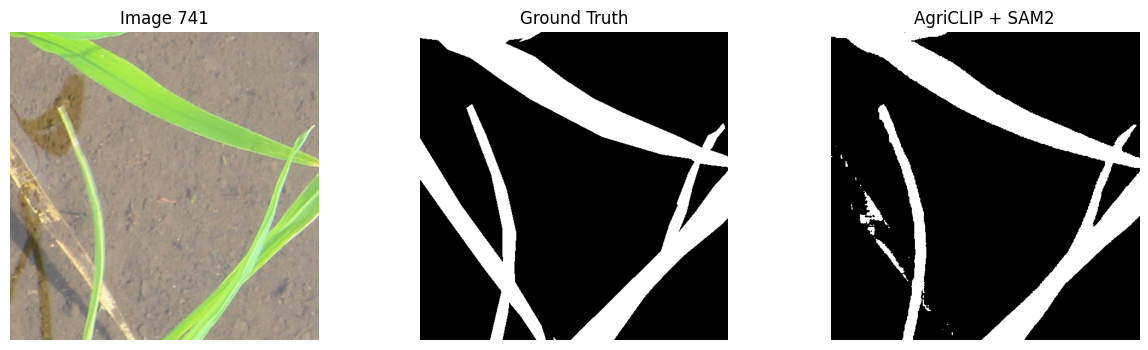

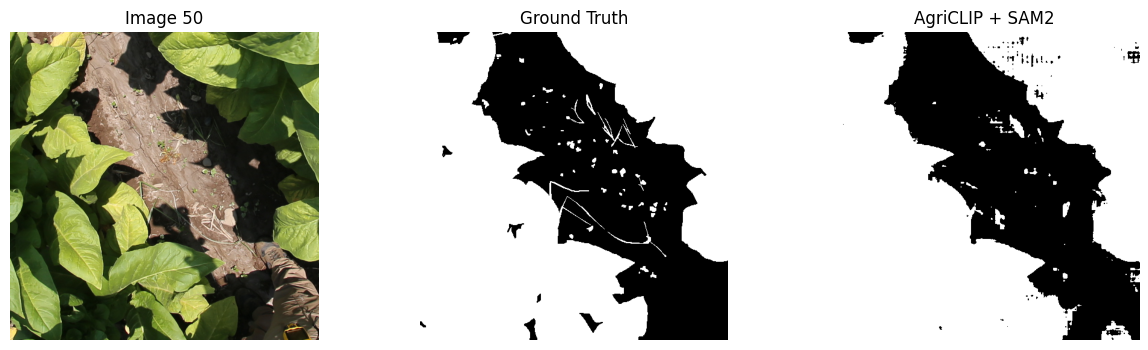

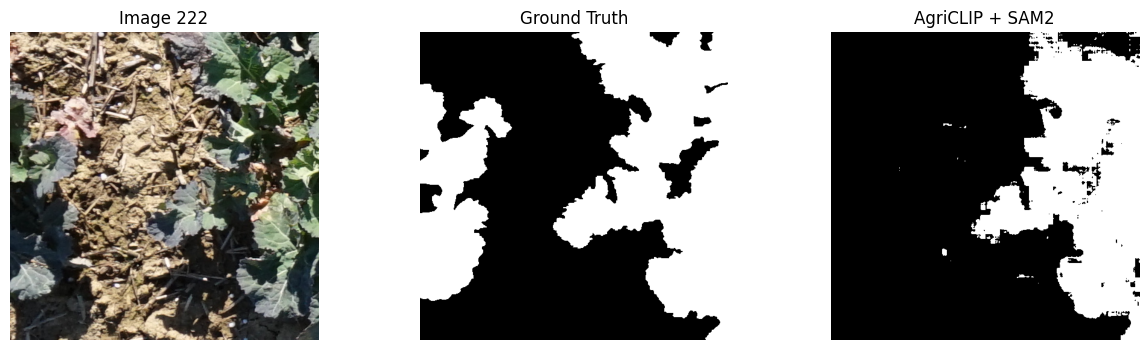

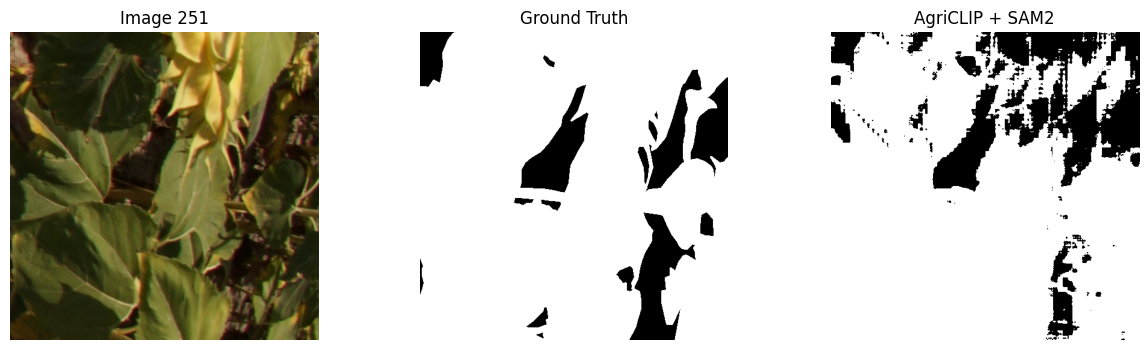

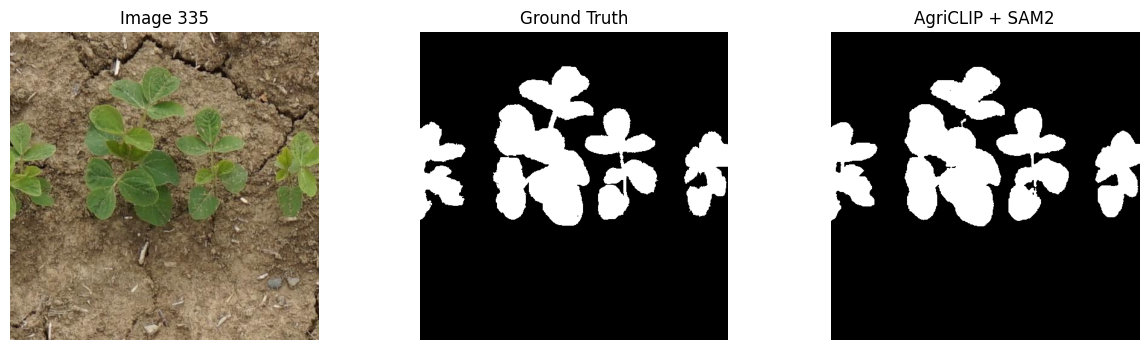

In [ ]:
#Visualize Random validation samples 
import random
import matplotlib.pyplot as plt


sample_ids = random.sample(
    range(len(val_hf)),
    5
)


for idx in sample_ids:

    image = get_image(
        idx,
        split=val_hf
    )

    gt = get_mask(
        idx,
        split=val_hf
    )


    pred = cv2.imread(
        str(
            MASK_DIR /
            f"{idx:04d}.png"
        ),
        0
    )

    pred = pred // 255


    plt.figure(
        figsize=(15,4)
    )


    plt.subplot(131)
    plt.imshow(image)
    plt.title(
        f"Image {idx}"
    )
    plt.axis("off")


    plt.subplot(132)
    plt.imshow(gt,cmap="gray")
    plt.title("Ground Truth")
    plt.axis("off")


    plt.subplot(133)
    plt.imshow(pred,cmap="gray")
    plt.title("AgriCLIP + SAM2")
    plt.axis("off")


    plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


comparison = pd.DataFrame({

    "Method":[
        "U-Net\nNo Prompt",
        "DeepLabV3\nNo Prompt",
        "SegFormer\nNo Prompt",
        "Pretrained SAM2\nAutoBox+3 Points",
        "Fine-tuned SAM2\nAutoBox+3 Points",
        "Fine-tuned SAM2\nGT Box",
        "AgriCLIP+SAM2\n(Ours)"
    ],


    "IoU":[
        68.19,
        68.55,
        69.42,
        26.09,
        84.93,
        87.25,
        75.85
    ],


    "Dice":[
        76.28,
        76.66,
        77.19,
        31.95,
        90.64,
        92.75,
        84.30
    ],


    "Precision":[
        np.nan,
        np.nan,
        np.nan,
        np.nan,
        88.89,
        90.60,
        90.43
    ],


    "Recall":[
        np.nan,
        np.nan,
        np.nan,
        np.nan,
        94.12,
        95.07,
        81.46
    ]

})


comparison

,Method,IoU,Dice,Precision,Recall
0,U-Net\nNo Prompt,68.19,76.28,NaN,NaN
1,DeepLabV3\nNo Prompt,68.55,76.66,NaN,NaN
2,SegFormer\nNo Prompt,69.42,77.19,NaN,NaN
3,Pretrained SAM2\nAutoBox+3 Points,26.09,31.95,NaN,NaN
4,Fine-tuned SAM2\nAutoBox+3 Points,84.93,90.64,88.89,94.12
5,Fine-tuned SAM2\nGT Box,87.25,92.75,90.60,95.07
6,AgriCLIP+SAM2\n(Ours),75.85,84.30,90.43,81.46


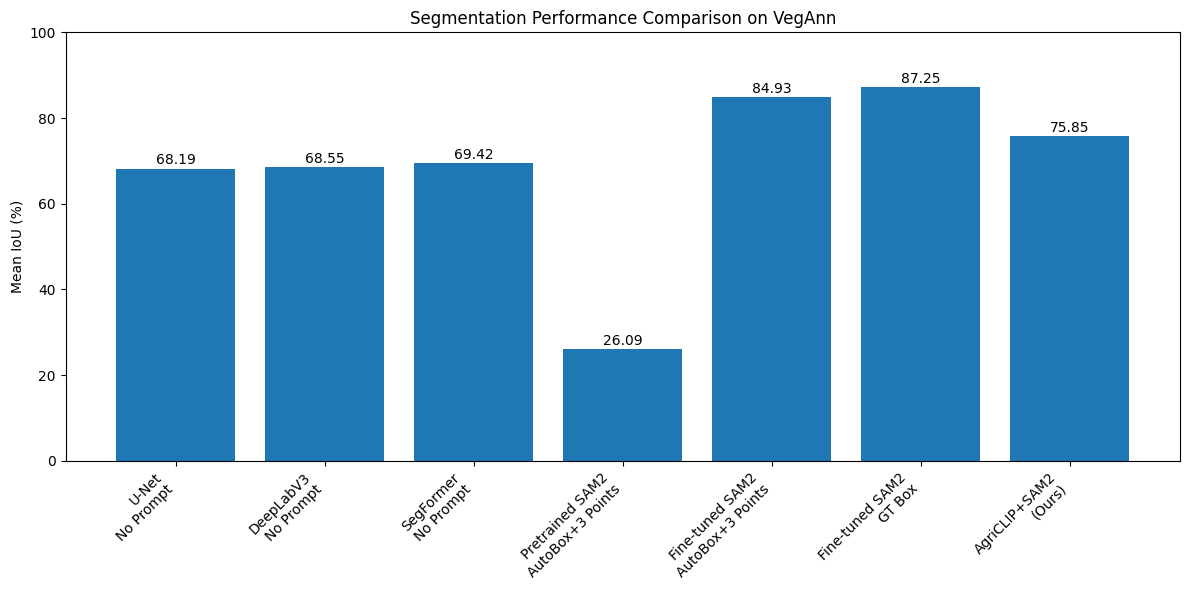

In [ ]:
plt.figure(
    figsize=(12,6)
)

plt.bar(
    comparison["Method"],
    comparison["IoU"]
)

plt.ylabel(
    "Mean IoU (%)"
)

plt.title(
    "Segmentation Performance Comparison on VegAnn"
)


plt.xticks(
    rotation=45,
    ha="right"
)

plt.ylim(
    0,
    100
)


for i,value in enumerate(comparison["IoU"]):

    plt.text(
        i,
        value+1,
        f"{value:.2f}",
        ha="center"
    )


plt.tight_layout()

plt.show()

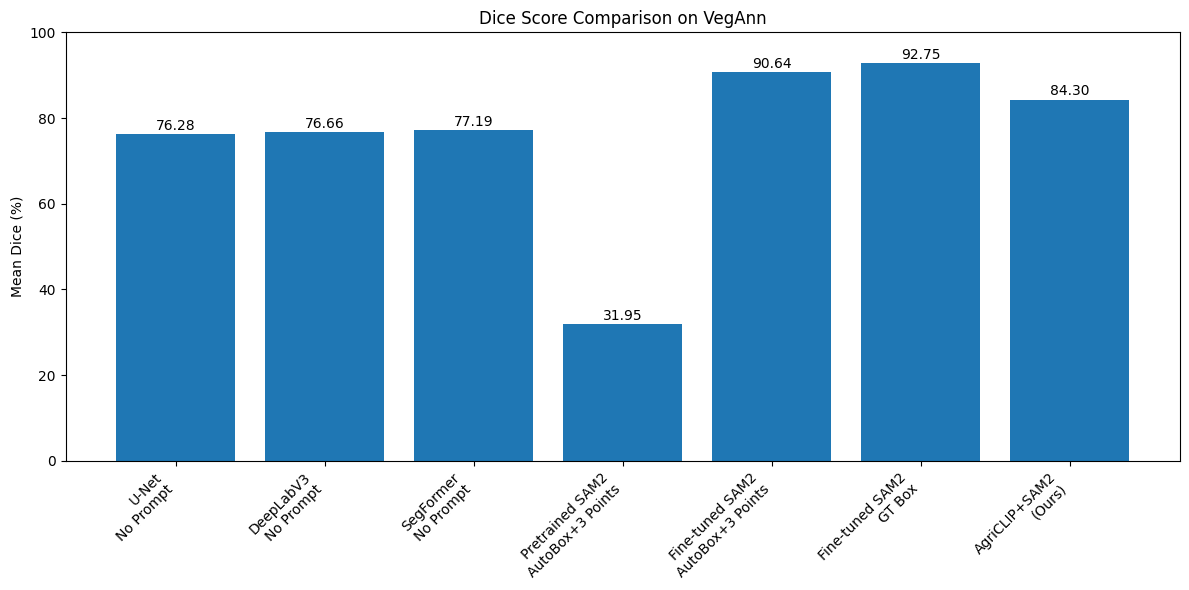

In [ ]:
plt.figure(
    figsize=(12,6)
)

plt.bar(
    comparison["Method"],
    comparison["Dice"]
)


plt.ylabel(
    "Mean Dice (%)"
)


plt.title(
    "Dice Score Comparison on VegAnn"
)


plt.xticks(
    rotation=45,
    ha="right"
)


plt.ylim(
    0,
    100
)


for i,value in enumerate(comparison["Dice"]):

    plt.text(
        i,
        value+1,
        f"{value:.2f}",
        ha="center"
    )


plt.tight_layout()

plt.show()

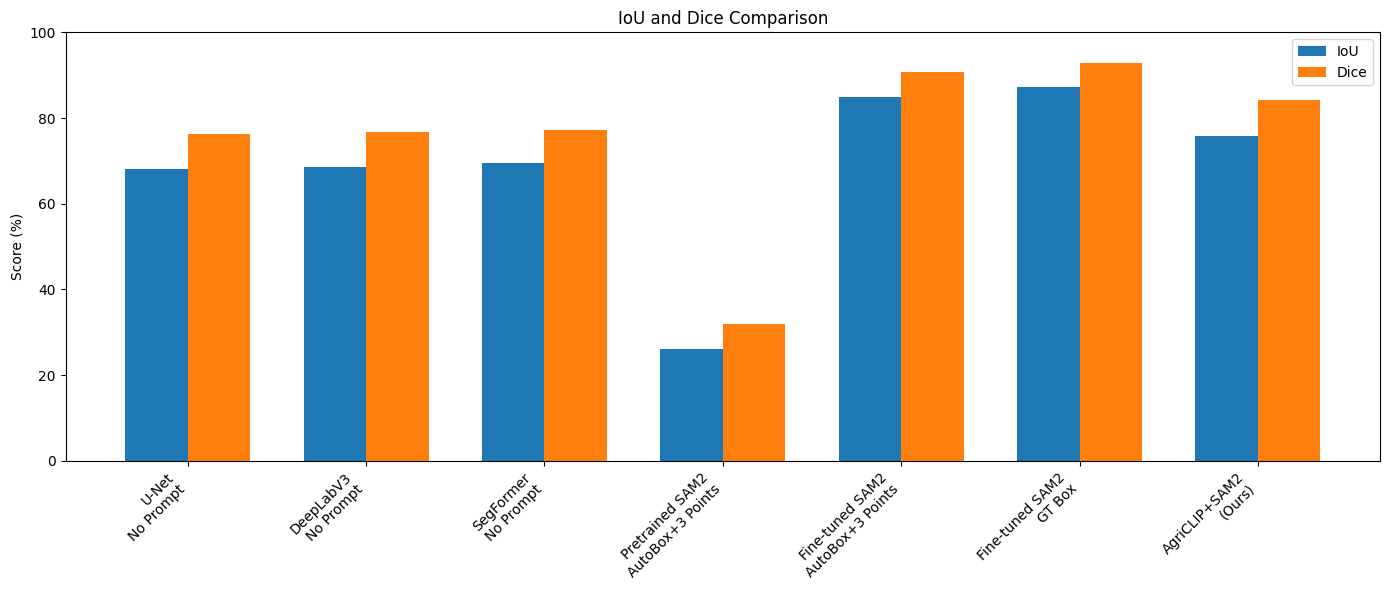

In [ ]:
x = np.arange(
    len(comparison)
)

width = 0.35


plt.figure(
    figsize=(14,6)
)


plt.bar(
    x-width/2,
    comparison["IoU"],
    width,
    label="IoU"
)


plt.bar(
    x+width/2,
    comparison["Dice"],
    width,
    label="Dice"
)


plt.ylabel(
    "Score (%)"
)


plt.title(
    "IoU and Dice Comparison"
)


plt.xticks(
    x,
    comparison["Method"],
    rotation=45,
    ha="right"
)


plt.ylim(
    0,
    100
)


plt.legend()


plt.tight_layout()

plt.show()

In [ ]:
comparison.to_csv(
    "vegann_segmentation_comparison.csv",
    index=False
)

# COMPARISOON WITH OTHER PROMPTS FOR SAM2 ON FULL VALIDATION SET
CENTER POINT
RANDOM BOX 

In [ ]:
import random


def generate_random_box(image):

    W, H = image.size


    # random box size
    box_w = random.randint(
        int(W*0.2),
        int(W*0.6)
    )

    box_h = random.randint(
        int(H*0.2),
        int(H*0.6)
    )


    # random position

    x1 = random.randint(
        0,
        W-box_w
    )

    y1 = random.randint(
        0,
        H-box_h
    )


    x2 = x1 + box_w
    y2 = y1 + box_h


    return np.array(
        [
            x1,
            y1,
            x2,
            y2
        ],
        dtype=np.int32
    )

In [ ]:
def generate_center_box(image, scale=0.5):

    W, H = image.size

    bw = int(W * scale)
    bh = int(H * scale)

    x1 = (W - bw) // 2
    y1 = (H - bh) // 2

    x2 = x1 + bw
    y2 = y1 + bh

    return np.array(
        [x1, y1, x2, y2],
        dtype=np.int32
    )

In [ ]:
@torch.no_grad()
def sam2_predict_box(
    image,
    box
):

    inputs = sam2_processor(
        images=image,
        input_boxes=[
            [
                box.tolist()
            ]
        ],
        return_tensors="pt",
    )


    inputs = {
        k:v.to(device)
        if torch.is_tensor(v)
        else v
        for k,v in inputs.items()
    }


    outputs = sam2_model(
        **inputs
    )


    best_idx = (
        outputs.iou_scores[0,0]
        .argmax()
        .item()
    )


    logits = outputs.pred_masks[
        0,
        0,
        best_idx
    ]


    probability = torch.sigmoid(
        logits
    )


    h = inputs["original_sizes"][0,0]
    w = inputs["original_sizes"][0,1]


    probability = F.interpolate(
        probability[None,None],
        size=(h,w),
        mode="bilinear",
        align_corners=False,
    )[0,0]


    mask = (
        probability > 0.5
    ).cpu().numpy().astype(np.uint8)


    confidence = (
        outputs.iou_scores[
            0,
            0,
            best_idx
        ]
        .item()
    )


    return mask, confidence

In [ ]:
random_results=[]


for idx in tqdm(range(len(val_hf))):

    image = get_image(
        idx,
        split=val_hf
    )


    gt_mask = get_mask(
        idx,
        split=val_hf
    )


    try:

        random_box = generate_random_box(
            image
        )


        pred_mask, confidence = sam2_predict_box(
            image,
            random_box
        )


        metrics = compute_binary_metrics(
            pred_mask,
            gt_mask
        )


        random_results.append(
            {
                "image_id":idx,

                "iou":metrics["iou"],

                "dice":metrics["dice"],

                "precision":metrics["precision"],

                "recall":metrics["recall"],

                "confidence":confidence
            }
        )


    except Exception as e:

        print(
            "Failed:",
            idx,
            e
        )


random_df=pd.DataFrame(
    random_results
)


print(random_df.mean())

  0%|          | 0/755 [00:00<?, ?it/s]

image_id      377.000000
iou             0.488301
dice            0.619475
precision       0.921085
recall          0.505549
confidence      0.852725
dtype: float64


In [ ]:
center_results = []

for idx in tqdm(range(len(val_hf))):

    image = get_image(idx, split=val_hf)
    gt_mask = get_mask(idx, split=val_hf)

    try:

        center_box = generate_center_box(image)

        pred_mask, confidence = sam2_predict_box(
            image,
            center_box
        )

        metrics = compute_binary_metrics(
            pred_mask,
            gt_mask
        )

        center_results.append({
            "image_id": idx,
            "iou": metrics["iou"],
            "dice": metrics["dice"],
            "precision": metrics["precision"],
            "recall": metrics["recall"],
            "confidence": confidence,
        })

    except Exception as e:
        print(f"Failed sample {idx}: {e}")

center_df = pd.DataFrame(center_results)

print(center_df.mean(numeric_only=True))

  0%|          | 0/755 [00:00<?, ?it/s]

image_id      377.000000
iou             0.422848
dice            0.567411
precision       0.909233
recall          0.438807
confidence      0.847337
dtype: float64


In [ ]:
print(point_df.shape)
print(point_df.columns)
print(point_df.head())

(0, 0)
RangeIndex(start=0, stop=0, step=1)
Empty DataFrame
Columns: []
Index: []


In [ ]:
print(point_df.head())
print(point_df.columns)
print(point_df.shape)

Empty DataFrame
Columns: []
Index: []
RangeIndex(start=0, stop=0, step=1)
(0, 0)


In [ ]:
ablation = pd.DataFrame({

    "Method":[
        "SAM2 + Random Box",
        "SAM2 + Center Box",
        "SAM2 + AgriCLIP Box",
        "SAM2 + GT Box"
    ],


    "IoU":[

        random_df.iou.mean()*100,

        center_df.iou.mean()*100,

        75.85,

        87.25
    ],


    "Dice":[

        random_df.dice.mean()*100,

        center_df.dice.mean()*100,

        84.30,

        92.75
    ]

})


ablation

,Method,IoU,Dice
0,SAM2 + Random Box,48.830102,61.947513
1,SAM2 + Center Box,42.284776,56.741096
2,SAM2 + AgriCLIP Box,75.850000,84.300000
3,SAM2 + GT Box,87.250000,92.750000


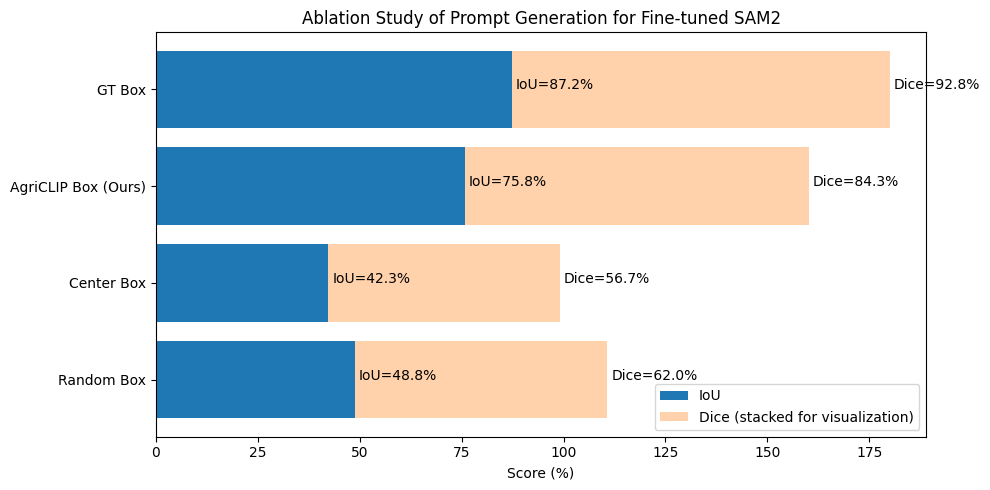

In [ ]:
import matplotlib.pyplot as plt

methods = [
    "Random Box",
    "Center Box",
    "AgriCLIP Box (Ours)",
    "GT Box"
]

iou = [48.83, 42.28, 75.85, 87.25]

dice = [61.95, 56.74, 84.30, 92.75]

fig, ax = plt.subplots(figsize=(10,5))

y = range(len(methods))

ax.barh(y, iou, label="IoU")
ax.barh(y, dice, left=iou, alpha=0.35, label="Dice (stacked for visualization)")

ax.set_yticks(y)
ax.set_yticklabels(methods)
ax.set_xlabel("Score (%)")
ax.set_title("Ablation Study of Prompt Generation for Fine-tuned SAM2")

for i, (i_val, d_val) in enumerate(zip(iou, dice)):
    ax.text(i_val + 1, i, f"IoU={i_val:.1f}%")
    ax.text(i_val + d_val + 1, i, f"Dice={d_val:.1f}%")

ax.legend()

plt.tight_layout()
plt.show()